<span style="font-size:14px">
    <h2>TaxiDriver - Algorithme de Q-Learning</h2>
    <p>Cet algorithme d'<b>apprentissage par renforcement (Q-Learning)</b> consiste à faire naviguer un taxi (l’agent) vers des passagers sur une grille 2D (l’environnement), de récupérer ces passagers et de les déposer chacun à une destination spécifique.</p>
    <p>On utilise une <b>Q-Table</b> afin d'apprendre une stratégie optimale à l'agent, lui permettant de se déplacer jusqu'à l'emplacement du passager, de le récupérer, de se rendre à la destination souhaitée par le passager et de l’y déposer (fin de l'épisode d'apprentissage), tout cela en effectuant le moins d'étapes possible : l'agent applique une stratégie d'exploration décroissante (epsilon-greedy), et met à jour les valeurs de Q selon la formule de Q-Learning.</p>
    <p>On peut ajuster les paramètres (tels que <b>alpha</b>, <b>gamma</b> ou <b>epsilon_decay</b>) afin d'améliorer la convergence et la stabilité de l'apprentissage.</p>
    <p>Explication de l'algorithme et des notions associées : https://www.geeksforgeeks.org/q-learning-in-python/</p>
</span>

<h5>Librairies Python</h5>

In [1]:
import numpy as np               # Numerical calculations, matrix management, random number generation, and so on...
import gymnasium as gym          # Provides a pre-designed environment where an agent can learn by interacting with its environment
import matplotlib.pyplot as plt  # 2D graphs generation, data visualization
import seaborn as sns            # Heatmaps (make tables easier to read)
import time                      # Time counting

# Libraries to display all graphs properly on the same picture
import tkinter as tk
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from IPython.display import display

<h5>Initialisation de l'environnement</h5>

In [2]:
# Default 5x5 map (the only one available)
env = gym.make("Taxi-v3", render_mode="rgb_array")

# To view the animated TaxiDriver interface
# env = gym.make("Taxi-v3", render_mode="human")

<h5>Paramètres de l'algorithme</h5>

In [3]:
alpha = 0.1                 # Learning rate : with a low learning rate, the agent is more stable, less prone to fluctuations (but slower to learn)
gamma = 0.9                 # Discount rate : determines the relative importance of future rewards compared to immediate rewards : should be as close to 1 as possible to avoid neglecting future rewards
epsilon = 1.0               # Epsilon-greedy parameter (epsilon starts to 1 <=> total exploration)
epsilon_min = 0.01          # Minimum epsilon value (minimum exploration probability)
epsilon_decay = 0.00001     # Factor controlling the progressive reduction of epsilon over the course of episodes
num_episodes = 10000        # Number of episodes (iterations)

<h5>Stockage des performances de l'algorithme</h5>

In [4]:
rewards_per_episode = np.zeros(num_episodes)    # Table holding the number of rewards per episode
steps_per_episode = np.zeros(num_episodes)      # Table holding the number of actions done per episode
epsilon_values = np.zeros(num_episodes)         # Table holding the epsilon value per episode
start_time = time.time()                        # Training time counter

<h5>Initialisation de la Q-Table</h5>

<p style="font-size:14px"><b>Taille de la Q-Table = (Nombre d'états, Nombre d'actions)</b></p>

<p style="font-size:14px">Il y a 25 positions possibles pour l'agent (l'environnement Taxi-v3 étant une grille 5x5), 5 emplacements possibles du passager (y compris le cas où le passager est dans le taxi) et 4 emplacements de destination. Ainsi, il y a 25 x 5 x 4 = <b>500 états possibles</b>.</p>

<p style="font-size:14px">L'agent peut effectuer <b>6 actions (gauche, bas, droite, haut, récupérer un passager, déposer un passager)</b>.</p>

<p style="font-size:14px">La Q-Table a donc une taille de <b>500 x 6 = 3000 valeurs Q.</b></p>

In [5]:
q_table = np.zeros((env.observation_space.n, env.action_space.n))

<h5>Stratégie epsilon-greedy</h5>

<p style="font-size:14px"><b>Au fur et à mesure qu'on fait diminuer epsilon, l'agent privilégiera de plus en plus l'exploitation plutôt que l'exploration au fil de son apprentissage.</b></p>
<p style="font-size:14px">En <b>exploration</b>, l'agent choisit aléatoirement (avec une probabilité de epsilon) parmi les 6 actions possibles, explorant de nouvelles possibilités pour apprendre de meilleures façons d'obtenir des récompenses. Cela permet à l'agent de découvrir de nouvelles stratégies et d'améliorer sa prise de décision au fil du temps.</p>
<p style="font-size:14px">En <b>exploitation</b>, l'agent choisit l’action ayant la plus grande valeur Q parmi les 6 valeurs de la Q-Table pour l’état actuel. Cela signifie que l'agent utilise ses connaissances actuelles pour maximiser les récompenses.</p>

In [6]:
def epsilon_greedy_policy(state, epsilon):
    if np.random.rand() < epsilon:
        return env.action_space.sample()     # Exploration
    else:
        return np.argmax(q_table[state, :])  # Exploitation

<h5>Entraînement de l'agent</h5>

<p style="font-size:14px"><b>On entraîne l'agent sur un nombre 'num_episodes' d'itérations.</b></p>
<p style="font-size:14px"><b>Gym 'truncated':</b> indique que l'agent peut effectuer 200 étapes max lors d'un épisode avant que ce dernier ne se termine automatiquement (pour éviter que l'agent reste bloqué indéfiniment).</p>
<p style="font-size:14px"><b>Gym 'terminated':</b> indique que l'agent a atteint l'objectif pour l'épisode courant (il a déposé le passager).</p>
<p style="font-size:14px">Les valeurs de la Q-Table (paires état/action) représentent les récompenses attendues pour l'exécution d'une action dans un état spécifique. L'équation de <b>mise à jour des valeurs de la Q-Table</b> est la suivante :</p>

$$
Q(s, a) \leftarrow Q(s, a) + \alpha \left( R(s, a) + \gamma \max_{a'} Q(s', a') - Q(s, a) \right)
$$

<p style="font-size:14px">où <b>s</b> représente l'état courant, <b>a</b> l'action choisie par l'agent, <b>s'</b> l'état suivant dans lequel se trouvera l'agent, <b>a'</b> la meilleure action pour s', <b>R</b> la récompense reçue pour avoir pris l'action dans l'état s.<p>

<p style="font-size:14px">A chaque épisode, epsilon est diminué de 'epsilon_decay', ce qui réduit la probabilité d'exploration et augmente celle d'exploitation des connaissances acquises dans la Q-Table. Cela permet à l'agent d'explorer au début, puis de se concentrer sur les actions optimales à mesure qu'il apprend.</p>

In [7]:
for episode in range(num_episodes):
    state = env.reset()[0]
    terminated = False
    truncated = False
    nb_steps = 0            # Number of steps for this episode
    total_reward = 0        # Total reward for this episode
    
    while (not terminated and not truncated):
        action = epsilon_greedy_policy(state, epsilon)

        # The env.step method returns :
        # - The agent's new state
        # - The reward earned for this action
        # - A Boolean indicating whether the episode is over (and metadata is ignored).
        next_state, reward, terminated, truncated, _ = env.step(action)
        
        # Q-Table update
        q_table[state, action] = q_table[state, action] + alpha * (reward + gamma * np.max(q_table[next_state, :]) - q_table[state, action])

        state = next_state
        nb_steps += 1
        total_reward += reward
        # -1 per step unless other reward is triggered
        # +20 delivering passenger
        # -10 for executing "pickup" and "drop-off" actions illegally

    # Statistics for this episode / Updates
    rewards_per_episode[episode] = total_reward
    steps_per_episode[episode] = nb_steps
    epsilon = max(epsilon_min, epsilon - epsilon_decay)
    epsilon_values[episode] = epsilon

    # Only captures last frame of the last episode
    if episode == (num_episodes - 1): 
        last_frame_img = env.render()

end_time = time.time()
duration = end_time - start_time
env.close()

<h5>Affichage des performances de l'algorithme</h5>

In [8]:
print("Mean rewards per episode :", np.mean(rewards_per_episode))
print("Mean number of steps per episode :", np.mean(steps_per_episode))
print("Total training duration :", duration, "secondes")

Mean rewards per episode : -674.042
Mean number of steps per episode : 181.5878
Total training duration : 52.481401443481445 secondes


<h2>Affichage des résultats</h2>
<p style="font-size:14px">On regroupe l'ensemble des tableaux et graphes obtenus sur une même image.</p>

<h5>Graphe représentant l'évolution des récompenses par épisode au fil des itérations</h5>

<p style="font-size:14px">On fait une <b>moyenne glissante</b> pour que le graphe soit lisible : un point représente 100 épisodes.</p>

In [9]:
def plot_rewards():
    rolling_average_rewards_per_episode = np.convolve(rewards_per_episode, np.ones(100)/100, mode='valid')
    
    fig = plt.figure()

    plt.plot(rolling_average_rewards_per_episode)
    plt.title("Rewards per episode (rolling average over 100 episodes)")
    plt.xlabel("Episode")
    plt.ylabel("Rewards")
    plt.grid(True)
    
    return fig

<h5>Graphe représentant l'évolution du nombre d'étapes nécessaires pour atteindre la récompense au fil des itérations</h5>

<p style="font-size:14px">On fait une <b>moyenne glissante</b> pour que le graphe soit lisible : un point représente 100 épisodes.</p>

In [10]:
def plot_steps():
    rolling_average_steps_per_episode = np.convolve(steps_per_episode, np.ones(100)/100, mode='valid')

    fig = plt.figure()
    
    plt.plot(rolling_average_steps_per_episode)
    plt.title("Number of steps per episode (rolling average over 100 episodes)")
    plt.xlabel("Episode")
    plt.ylabel("Number of steps")
    plt.grid(True)

    return fig

<h5>Graphe représentant l'évolution de la valeur d'epsilon au fur et à mesure des épisodes</h5>

In [11]:
def plot_epsilon():
    fig = plt.figure()

    plt.plot(epsilon_values)
    plt.title("Epsilon evolution through iterations")
    plt.xlabel("Episode")
    plt.ylabel("Epsilon value")
    plt.grid(True)

    return fig

<h5>Image représentant la dernière frame de l'apprentissage</h5>

In [12]:
def get_last_frame():
    fig = plt.figure()
    
    plt.imshow(last_frame_img)
    plt.axis("off")
    plt.title("Last TaxiDriver frame")

    return fig

<h5>Regroupement des résultats</h5>

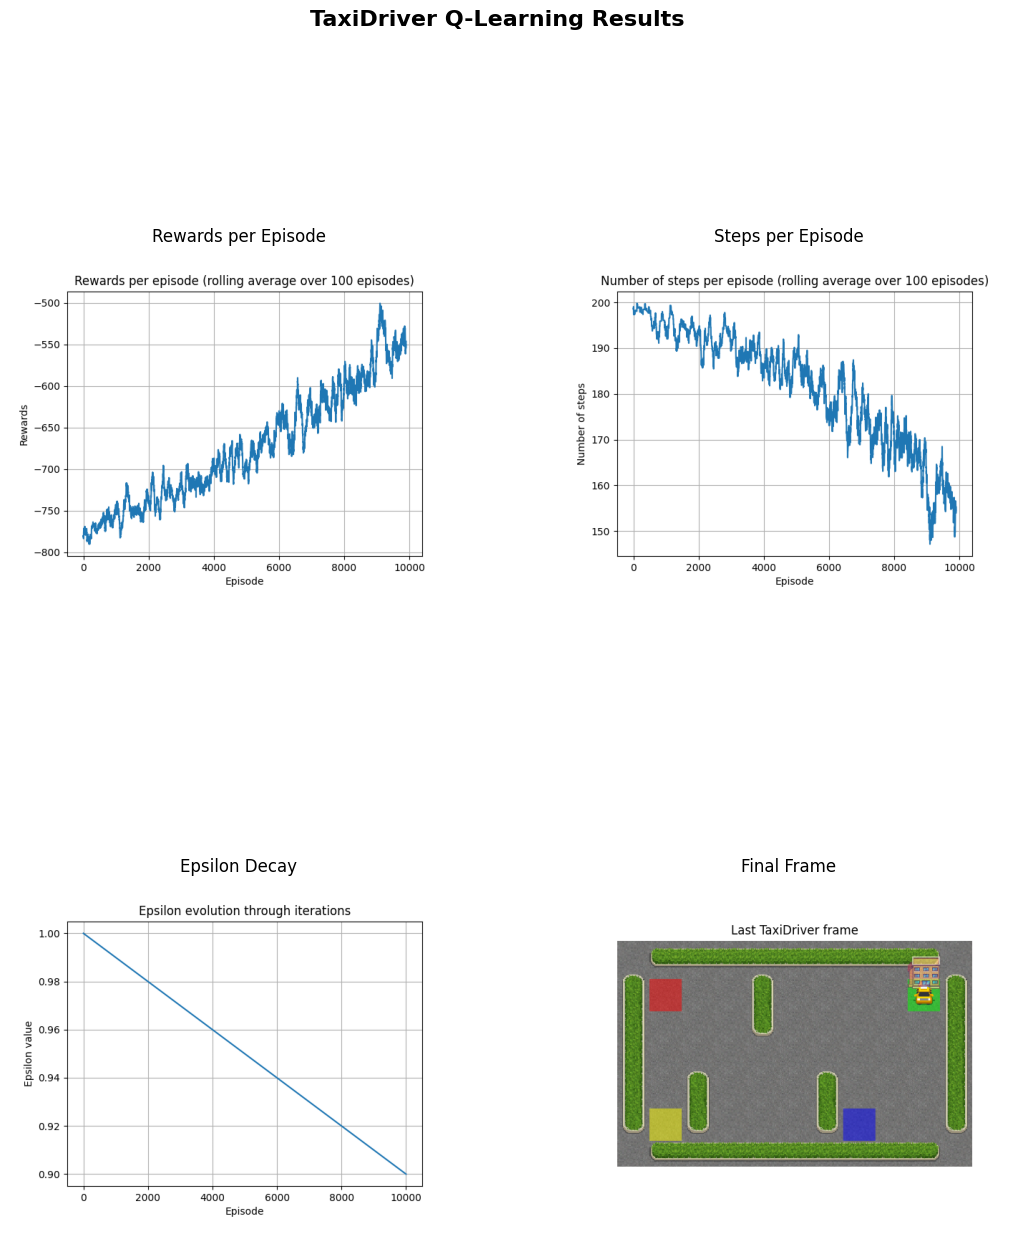

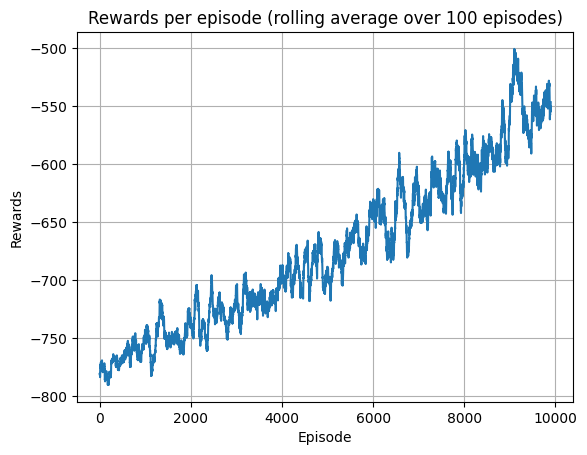

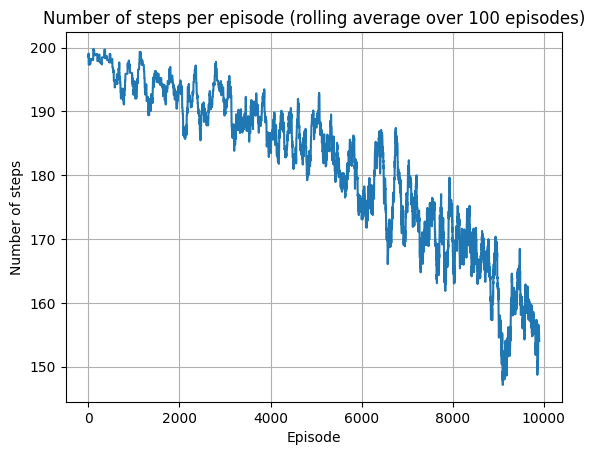

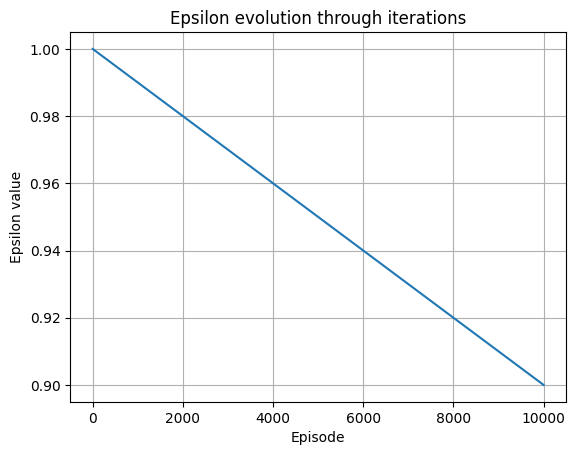

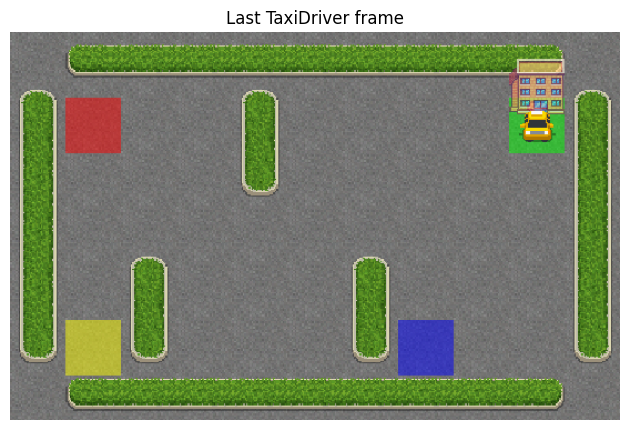

In [13]:
# 2x2 grid initialization
fig, axes = plt.subplots(2, 2, figsize=(13, 15))
fig.suptitle("TaxiDriver Q-Learning Results", fontsize=16, fontweight="bold")

fig1 = plot_rewards()
fig2 = plot_steps()
fig3 = plot_epsilon()
fig4 = get_last_frame()

# Force figures render to avoid issues
for figure in [fig1, fig2, fig3, fig4]:
    figure.canvas.draw()

# Display graphs on corresponding axes
axes[0, 0].imshow(fig1.canvas.buffer_rgba())
axes[0, 0].set_title("Rewards per Episode")

axes[0, 1].imshow(fig2.canvas.buffer_rgba())
axes[0, 1].set_title("Steps per Episode")

axes[1, 0].imshow(fig3.canvas.buffer_rgba())
axes[1, 0].set_title("Epsilon Decay")

axes[1, 1].imshow(fig4.canvas.buffer_rgba())
axes[1, 1].set_title("Final Frame")

# Delete axes and graduations marks around images
for ax in axes.flatten():  
    ax.axis("off")  

plt.tight_layout()
plt.show()